# Closing the loop: landing

*Section "Closing the loop: landing scenarios" of the paper.*

To close the sensorimotor loop, the camera descends onto the ground plane and has to **touch the ground with the
best compromise between speed and softness**: the faster it lands the shorter the episode, but the harder it
touches the ground. The softness is measured by the **speed at contact**. The camera follows a straight path at a
constant angle of attack $\gamma$ (90 degrees is a vertical descent) without roll or pitch, and its speed along the
path is the commanded speed plus the same exogenous perturbation as before: a slow diffusion and gusts that
arrive at a hazard rate. This is the benchmark **AVB4** (`landing`).

## The model

With the height $z$ above the ground and the speed $v$ along the path, the vertical velocity is
$v_z = -v \sin\gamma$ (positive upwards). The optic flow around the nadir expands with a **divergence rate**

$$D = -\frac{v_z}{z} = \frac{v \sin\gamma}{z},$$

which is the inverse of the time to contact (`estimate_time_to_contact`) and can be measured by the camera without
knowing $z$ or $v$, but with the visual angle of the camera, which the model reads from its observation.

**Constant divergence.** The strategy observed in honeybees and studied by Guido de Croon keeps the divergence
constant, $D = C$ (Izzo & de Croon, 2012). The height then obeys $\dot z = -C z$, so that

$$z(t) = z_0\,e^{-C t}, \qquad v_z(t) = -C\,z(t) :$$

**both the height and the vertical velocity decay exponentially**, which gives a smooth and safe landing. The
ground is reached (height $z_c$) at the time and with the speed

$$T = \frac{1}{C}\ln\frac{z_0}{z_c}, \qquad v_c = C\,z_c, \qquad\text{hence}\qquad v_c\,T = z_c \ln\frac{z_0}{z_c}.$$

The set point $C$ is the knob of the **trade-off**: a larger $C$ is faster ($T$ decreases) and harder ($v_c$
increases).

**Control law.** The divergence $\hat D$ is estimated from two successive frames. The commanded speed $v$ obeys

$$\frac{d \ln v}{dt} = -\hat D + \kappa\,(C - \hat D),$$

the first term being the feed-forward decay that holds $D$ constant and the second one a feedback that regulates it
to $C$: with $L = \ln(v/z)$ the dynamics is $\dot L = \kappa\,(C - D)$, stable for $\kappa > 0$.

**Reference.** Without control, the camera keeps its nominal speed $v_0$ (perturbed): $T = z_0/(v_0 \sin\gamma)$
and the contact speed is about $v_0$, so $v_c\,T \approx z_0$, much harder at the same duration.

| Symbol | Name in the code | Default value | Role |
|--------|------------------|---------------|------|
| $\gamma$ | `attack_angle` | 90 deg | angle between the path and the ground |
| $z_0$ | `altitude0` | 10 m (with 10 % of variation) | initial height |
| $v_0$ | `speed0` | 2 m/s | nominal speed along the path |
| $z_c$ | `z_contact` | 0.05 m | height under which the ground is touched |
| | `v_safe` | 0.5 m/s | largest speed at contact of a successful landing |
| $\Delta t$ | `dt` | 1/30 s | duration of a step of the camera |
| $k$ | `control_every` | 1 | camera steps per decision of the model (the last speed command is held in between) |
| $\tau$, $\sigma_\mathrm{OU}$ | `Perturbation` | 1 s, 0.1 m/s | slow diffusion of the speed |
| $\lambda$, $\sigma_\mathrm{jump}$ | `Perturbation` | 0.2 s$^{-1}$, 0.3 m/s | hazard rate and amplitude of the gusts |
| | `Perturbation.jump_tau` | 1 s | a gust relaxes with this time constant |
| $C$ | `ConstantDivergenceLandingModel.divergence` | 0.5 s$^{-1}$ | set point of the divergence |
| $\kappa$ | `ConstantDivergenceLandingModel.kappa` | 1 | gain of the feedback |
| $VA$ | `ConstantDivergenceLandingModel.visual_angle` | `None` (the one of the camera, 45 deg) | visual angle of the image width, read from `Observation.visual_angle` |
| | `depth_exponent` | 0 | no attenuation with the distance (the gain does not change with the altitude) |

In [1]:
import pathlib
import sys

ROOT = pathlib.Path.cwd().parent          # the repository, when the package is not installed
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np

import ActiveVisionBenchmark as avb
from functools import partial

cached = partial(avb.cached, cache_dir=ROOT / "cache")
save = partial(avb.save_figure, directory=ROOT / "figures")

# Colour-blind safe palette (Okabe-Ito)
BLUE, ORANGE, GREEN, GREY = "#0072B2", "#E69F00", "#009E73", "#666666"

import os

from IPython.display import Markdown

N_JOBS = os.cpu_count()
SEED = 3

## The task

The ventral view at three altitudes: the texture appears larger as the camera descends, and the flow expands from the
centre of the image (its ground truth is shown in the section on the event camera below).

[]

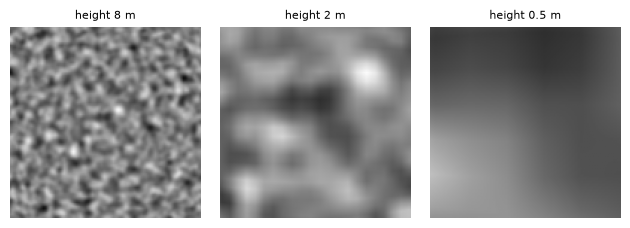

In [2]:
LANDING = dict(size=128, noise_std=0.01)
task = avb.LandingTask(avb.MotionCloudStimulus(), **LANDING)

fig, axes = avb.new_figure(16, 5.5, 1, 3)
for ax, altitude in zip(axes, (8.0, 2.0, 0.5)):
    ax.imshow(task.render(avb.Pose(altitude=altitude), seed=0)[0].cpu().numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"height {altitude:g} m")
    ax.axis("off")
save(fig, "04_views")

### Benchmark AVB4: `landing`

The camera descends onto the ground plane and has to **land fast and softly**. This benchmark is **active**: the
model commands the speed. The table above gives the symbols and the default values of the model; here are the
values that the benchmark fixes.

| Symbol | Name in the code | Value | Role |
|--------|------------------|-------|------|
| $\gamma$ | `attack_angle` | 90 deg | vertical descent |
| $z_0$ | `altitude0` | 10 m (with 10 % of variation) | initial height |
| $v_0$ | `speed0` | 2 m/s | nominal speed along the path |
| $z_c$ | `z_contact` | 0.05 m | height under which the ground is touched |
| | `v_safe` | 0.5 m/s | largest speed at contact of a successful landing |
| | `v_max` | 10 m/s | largest speed along the path |
| | `max_time` | 60 s | duration after which an episode is a failure |
| $\Delta t$ | `dt` | 1/30 s | duration of a step |
| $\tau$, $\sigma_\mathrm{OU}$ | `perturbation.tau`, `perturbation.sigma_ou` | 1 s, 0.1 m/s | slow diffusion of the speed |
| $\lambda$, $\sigma_\mathrm{jump}$ | `perturbation.hazard_rate`, `perturbation.sigma_jump` | 0.2 s$^{-1}$, 0.3 m/s | gusts, which relax with `jump_tau` = 1 s |
| | `size`, `noise_std` | 128 pixels, 0.01 | image and its noise (the `LANDING` dictionary) |

**Dataset:** 100 episodes, seed 3. **Reference models:** `ConstantSpeedLandingModel` ($v_0 = 2$ m/s) and
`ConstantDivergenceLandingModel` ($C = 1$ s$^{-1}$). **Metrics:** success rate (contact at a speed below `v_safe`), time
to land (s) and speed at contact (m/s); the optional cost $J = T + w\,v_c$ picks a point of the front of the trade-off.
The cell below prints the values that the task actually uses.


In [3]:
for name in ("size", "visual_angle", "attack_angle", "altitude0", "speed0", "z_contact", "v_safe", "v_max", "dt",
             "depth_exponent", "noise_std"):
    print(f"{name:17s} {getattr(task, name)}")
print(f"{'max_time':17s} {task.n_steps * task.dt:.0f}  (n_steps = {task.n_steps})")
print(f"{'perturbation':17s} {task.perturbation}")
print(f"{'seed':17s} {SEED}")

size              (128, 128)
visual_angle      45.0
attack_angle      90.0
altitude0         10.0
speed0            2.0
z_contact         0.05
v_safe            0.5
v_max             10.0
dt                0.03333333333333333
depth_exponent    0.0
noise_std         0.01
max_time          60  (n_steps = 1800)
perturbation      Perturbation(dt=0.03333333333333333, tau=1.0, sigma_ou=0.1, mean=0.0, hazard_rate=0.2, sigma_jump=0.3, limit=None, seed=None, jump_tau=1.0)
seed              3


## One episode

A trial starts at about 10 m of height. Two models land: the nominal speed, kept constant (it is perturbed), and
the constant divergence with the set point $C = 1\ \mathrm{s}^{-1}$. The figure shows the height, the speed
and the divergence, estimated from the images and true.

The constant divergence starts with a transient, since the divergence of the nominal descent (0.2 s$^{-1}$) is far
below the set point and the speed has to build up. It then follows the exponential descent, and the speed decays with
the height. Close to the ground (the last metre) the estimate of the divergence is noisier and is too low: the ground
texture is a single spatial scale, so that the image of a ground that is a few tens of centimetres wide has little
structure left.

[]

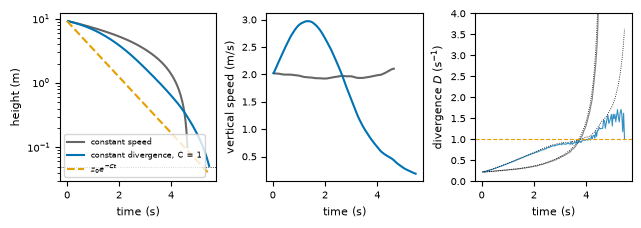

In [4]:
import math

def rollout(task, model, trial):
    """Play one episode; the true height and speed are ground truth, for the figure only."""
    obs = task.reset(trial)
    model.reset(trial.seed)
    rows, done = [], False
    while not done:
        z = obs.info["altitude"]
        d_hat = avb.estimate_divergence(obs.previous, obs.image, task.visual_angle, task.dt) if obs.previous is not None else np.nan
        action = model.act(obs)
        obs, done, info = task.step(action)
        rows.append((obs.t, z, info["speed"], d_hat))
    return np.array(rows).T          # time, height, speed, estimated divergence

C = 1.0
trial = task.generate_trial(SEED)
episodes = {
    "constant speed": rollout(task, avb.ConstantSpeedLandingModel(2.0), trial),
    f"constant divergence, C = {C:g}": rollout(task, avb.ConstantDivergenceLandingModel(divergence=C), trial),
}
z0 = trial.metadata["altitude0"]

fig, axes = avb.new_figure(16, 5.5, 1, 3)
for (name, (t, z, v, d_hat)), color in zip(episodes.items(), (GREY, BLUE)):
    axes[0].semilogy(t, z, color=color, label=name)
    axes[1].plot(t, v * np.sin(math.radians(task.attack_angle)), color=color)
    axes[2].plot(t, d_hat, color=color, lw=0.8, alpha=0.8, label="estimated")
    axes[2].plot(t, v * np.sin(math.radians(task.attack_angle)) / z, color="k", lw=0.6, ls=":")
t = np.linspace(0, episodes[f"constant divergence, C = {C:g}"][0].max(), 100)
axes[0].semilogy(t, z0 * np.exp(-C * t), color=ORANGE, ls="--", label=r"$z_0 e^{-Ct}$")
axes[0].axhline(task.z_contact, color="k", lw=0.6, ls=":")
axes[0].set_xlabel("time (s)"); axes[0].set_ylabel("height (m)"); axes[0].legend(fontsize=6)
axes[1].set_xlabel("time (s)"); axes[1].set_ylabel("vertical speed (m/s)")
axes[2].set_xlabel("time (s)"); axes[2].set_ylabel(r"divergence $D$ (s$^{-1}$)")
axes[2].axhline(C, color=ORANGE, ls="--", lw=0.8)
axes[2].set_ylim(0, 4)
save(fig, "04_episode")

## Watching the landings

The video below plays the **same trial** with three models, side by side: the constant speed, and the constant divergence
with $C = 0.5$ and $C = 2\ \mathrm{s}^{-1}$ (`const. div.`). Each panel is the ventral view of the camera, with its
height $z$ at the bottom right. A model that has touched the ground keeps its last frame and shows the speed at
contact, until the slowest one lands.

As in the passive navigation, the **dot** is the true focus of expansion, which for a vertical descent is the nadir, at
the centre of the image, and the **circle** is the FoE that an observer estimates from the images (`FlowHeadingModel`,
which only watches). The estimate is accurate while the ground texture is well resolved, and it drifts away in the last
metres, where the image of the ground has little structure left. The same limit makes the estimate of the divergence
noisy close to the ground (see the section above).

In [5]:
video_task = avb.LandingTask(avb.MotionCloudStimulus(), size=192, noise_std=0.01, device="cpu")
video_models = {
    "constant speed": avb.ConstantSpeedLandingModel(2.0),
    "const. div. C=0.5": avb.ConstantDivergenceLandingModel(divergence=0.5),
    "const. div. C=2": avb.ConstantDivergenceLandingModel(divergence=2.0),
}
path = avb.landing_video(video_task, video_models, "04_landing", directory=ROOT / "figures", seed=SEED)
avb.show_video(path)

## 100 episodes

The constant speed fails to land softly (the speed at contact is the nominal speed, above `v_safe`). The constant
divergence reaches the ground at a speed that is limited by the gusts that perturb the speed.

In [6]:
N_EPISODES = avb.scaled(100, 8)
models = {"constant speed": avb.ConstantSpeedLandingModel(2.0),
          "constant divergence (C = 1)": avb.ConstantDivergenceLandingModel(divergence=1.0)}
bench = avb.ActiveBenchmark(task)
trials = bench.generate_dataset(N_EPISODES, seed=SEED)
results = cached("04_episodes", dict(landing=LANDING, divergence=1.0, speed0=2.0, n_episodes=N_EPISODES, seed=SEED),
                 lambda: bench.evaluate(trials, models, n_jobs=N_JOBS))

rows = ["| model | success rate | time to land (s) | speed at contact (m/s) |", "|---|---|---|---|"]
for name, r in results.items():
    rows.append(f"| {name} | {r.success_rate:.2f} | {r.mean_time_to_land:.2f} | {r.mean_contact_speed:.3f} |")
Markdown("\n".join(rows))

| model | success rate | time to land (s) | speed at contact (m/s) |
|---|---|---|---|
| constant speed | 0.00 | 5.02 | 2.024 |
| constant divergence (C = 1) | 0.98 | 6.09 | 0.176 |

[]

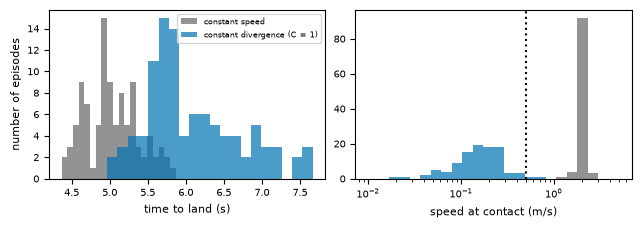

In [7]:
fig, axes = avb.new_figure(16, 5.5, 1, 2)
for (name, res), color in zip(results.items(), (GREY, BLUE)):
    axes[0].hist([r.info["time_to_land"] for r in res.trial_results], bins=20, color=color, alpha=0.7, label=name)
    axes[1].hist([r.info["contact_speed"] for r in res.trial_results], bins=np.geomspace(0.01, 5, 25), color=color, alpha=0.7)
axes[0].set_xlabel("time to land (s)"); axes[0].set_ylabel("number of episodes"); axes[0].legend(fontsize=6)
axes[1].set_xscale("log"); axes[1].axvline(task.v_safe, color="k", ls=":"); axes[1].set_xlabel("speed at contact (m/s)")
save(fig, "04_distributions")

## The trade-off between speed and softness

Sweeping the set point $C$ draws the **front of the compromise**: a larger $C$ gives a shorter episode and a harder
contact. The nominal speed $v_0$ does the same for the constant speed, with a much worse trade-off: at the same
duration, the speed at contact is far higher. The curves are the ideal ones of the model above (without gusts),
$v_c = z_c \ln(z_0/z_c)/T$ for the constant divergence and $v_c = z_0/T$ for the constant speed. The floor of the
contact speed of the constant divergence is set by the gusts, which add their speed to the commanded one.

[]

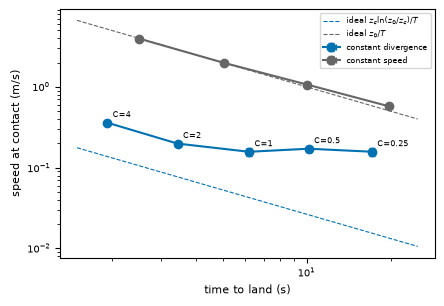

In [8]:
CS = [0.25, 0.5, 1.0, 2.0, 4.0]
SPEEDS = [0.5, 1.0, 2.0, 4.0]
N_FRONT = avb.scaled(40, 6)

def front():
    out = {"constant divergence": [], "constant speed": []}
    bench = avb.ActiveBenchmark(task)
    trials = bench.generate_dataset(N_FRONT, seed=SEED + 1)
    for c in CS:
        out["constant divergence"].append(bench.run(avb.ConstantDivergenceLandingModel(divergence=c), trials, n_jobs=N_JOBS))
    for v in SPEEDS:
        slow = avb.LandingTask(avb.MotionCloudStimulus(), speed0=v, **LANDING)
        out["constant speed"].append(avb.ActiveBenchmark(slow).run(avb.ConstantSpeedLandingModel(v), trials, n_jobs=N_JOBS))
    return out

front_results = cached("04_front", dict(landing=LANDING, cs=CS, speeds=SPEEDS, n_episodes=N_FRONT, seed=SEED + 1), front)

fig, ax = avb.new_figure(11, 7.5)
means = {}
for (family, results_), color in zip(front_results.items(), (BLUE, GREY)):
    T = np.array([[r.info["time_to_land"] for r in res.trial_results] for res in results_])
    V = np.array([[r.info["contact_speed"] for r in res.trial_results] for res in results_])
    means[family] = (T.mean(1), V.mean(1))
    ax.errorbar(T.mean(1), V.mean(1), xerr=T.std(1) / np.sqrt(T.shape[1]), yerr=V.std(1) / np.sqrt(V.shape[1]),
                fmt="o-", color=color, label=family, capsize=2)
duration = np.geomspace(1.5, 25, 50)
z0, zc = task.altitude0, task.z_contact
ax.plot(duration, zc * np.log(z0 / zc) / duration, color=BLUE, ls="--", lw=0.8, label=r"ideal $z_c\ln(z_0/z_c)/T$")
ax.plot(duration, z0 / duration, color=GREY, ls="--", lw=0.8, label=r"ideal $z_0/T$")
for c, t_, v_ in zip(CS, *means["constant divergence"]):
    ax.annotate(f"C={c:g}", (t_, v_), textcoords="offset points", xytext=(4, 4), fontsize=6)
ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel("time to land (s)"); ax.set_ylabel("speed at contact (m/s)")
ax.legend(fontsize=6)
save(fig, "04_front")

A scalar cost, $J = T + w\,v_c$ with the weight $w$ (in seconds per m/s), picks one point of the front. The
best set point depends on how much the contact speed counts with respect to the duration:

In [9]:
rows = ["| weight $w$ (s per m/s) | best $C$ (s$^{-1}$) | $T$ (s) | $v_c$ (m/s) | $J$ (s) |", "|---|---|---|---|---|"]
for w in (0.0, 5.0, 20.0, 100.0):
    stats = []
    for c, res in zip(CS, front_results["constant divergence"]):
        T = np.mean([r.info["time_to_land"] for r in res.trial_results]); V = np.mean([r.info["contact_speed"] for r in res.trial_results])
        stats.append((T + w * V, c, T, V))
    J, c, T, V = min(stats)
    rows.append(f"| {w:g} | {c:g} | {T:.2f} | {V:.3f} | {J:.2f} |")
Markdown("\n".join(rows))

| weight $w$ (s per m/s) | best $C$ (s$^{-1}$) | $T$ (s) | $v_c$ (m/s) | $J$ (s) |
|---|---|---|---|---|
| 0 | 4 | 1.92 | 0.361 | 1.92 |
| 5 | 4 | 1.92 | 0.361 | 3.73 |
| 20 | 2 | 3.44 | 0.199 | 7.41 |
| 100 | 1 | 6.21 | 0.157 | 21.95 |

## Simulated event-camera data

The paper shows real data of a landing with an event camera (Nunes et al., 2023). This task also simulates
the ventral view of such a camera. Each pixel keeps a **reference log-luminance**. It emits an event when the
current log-luminance differs from it by more than a threshold $\theta$, with a polarity (ON when it brightens, OFF
when it darkens), and **its reference is then moved by $\theta$**: a change is counted once, and a pixel that keeps
changing keeps emitting events. There is at most one event per pixel and per step of 1/30 s.

The model is adapted from `make_events` of the notebook `FastMotionDetection.ipynb` of Grimaldi & Perrinet (2023,
<https://github.com/SpikeAI/2023_GrimaldiPerrinet_HeterogeneousDelaySNN>). Like it, the threshold is **relative to
the scene**: $\theta = k\,\sigma$, where $\sigma$ is the standard deviation of the temporal change of the
log-luminance and $k$ is the `selectivity`. Unlike it, the threshold is subtracted from the reference stored in the
pixel, so that a remainder is not lost, instead of from the next temporal difference. The dense and smooth texture
needs a large selectivity: with $k = 1$ almost every pixel (70 to 84 %) spikes in 0.1 s, with $k = 6$
($\theta \approx 0.25$) only 9 to 22 % do.

The figures show the events accumulated over the 0.1 s that end at the height of 2 m, and the ground-truth flow
of the same step. These figures are **simulated**; they do not replace the real ones of the paper.

threshold 0.251 in log-luminance; 5476 events out of 36864 pixels in 0.1 s


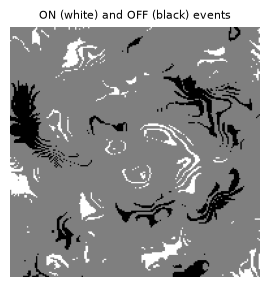

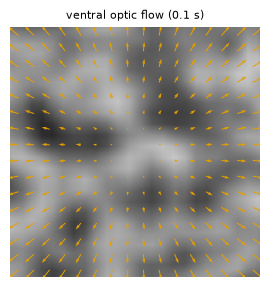

In [10]:
events_task = avb.LandingTask(avb.MotionCloudStimulus(), size=192, noise_std=0.0, speed0=2.0)
events_task.prepare(1)

def simulate_events(views, selectivity):
    """Spikes of an event camera that watches the frames *views* (steps, rows, columns), in [0, 1].

    Each pixel keeps a reference log-luminance. It spikes when the log-luminance differs from it by more than the
    threshold (+1 ON, -1 OFF, at most one spike per step) and **its reference is then moved by one threshold**, so
    that a change is counted once and a pixel that keeps changing keeps spiking. The threshold is relative to the
    scene, as in make_events of FastMotionDetection.ipynb (Grimaldi & Perrinet, 2023,
    https://github.com/SpikeAI/2023_GrimaldiPerrinet_HeterogeneousDelaySNN): selectivity times the standard
    deviation of the temporal change of the log-luminance.
    """
    log_luminance = np.log(np.asarray(views, dtype=float) + 0.05)
    threshold = selectivity * np.diff(log_luminance, axis=0).std()
    reference = log_luminance[0].copy()
    polarity = np.zeros(log_luminance.shape, dtype=np.int8)
    for k in range(1, len(log_luminance)):
        difference = log_luminance[k] - reference
        polarity[k] = (difference > threshold).astype(np.int8) - (difference < -threshold).astype(np.int8)
        reference += polarity[k] * threshold                      # reset of the pixel at each spike
    return polarity, threshold

def event_frame(polarity, k, window):
    """Image (white ON, black OFF, grey none) and number of spikes of the *window* steps that end at step *k*."""
    recent = polarity[k - window + 1: k + 1]
    net = np.sign(recent.sum(0))
    return np.where(net > 0, 1.0, np.where(net < 0, 0.0, 0.5)), int(np.abs(recent).sum())

DT_EVENTS = events_task.dt                                         # one frame per camera step (s)
WINDOW = 3                                                         # steps shown together: 0.1 s
SELECTIVITY = 6.0                                                  # threshold, in standard deviations of the temporal change
Z_START, Z_END = 4.0, 0.4                                          # descent of the simulation (m)

n_frames = int((Z_START - Z_END) / (events_task.speed0 * DT_EVENTS))
poses = [avb.Pose(altitude=Z_START - events_task.speed0 * DT_EVENTS * k, distance=events_task.speed0 * DT_EVENTS * k)
         for k in range(n_frames)]
views = np.array([events_task.render(p)[0].cpu().numpy() for p in poses])
polarity, threshold = simulate_events(views, SELECTIVITY)

k_show = int(round((Z_START - 2.0) / (events_task.speed0 * DT_EVENTS)))      # the frame at the height of 2 m
event_image, n_events = event_frame(polarity, k_show, WINDOW)

fig, ax = avb.new_figure(7, 7)
ax.imshow(np.full(event_image.shape + (3,), 0.5));
ax.imshow(np.where(event_image == 0.5, np.nan, event_image), cmap="gray", vmin=0, vmax=1)
ax.set_title("ON (white) and OFF (black) events")
ax.axis("off")
save(fig, "04_landing_sim_events")

start = k_show - WINDOW                                            # the 0.1 s of the events begin here
ds = events_task.speed0 * DT_EVENTS * WINDOW                       # distance travelled in 0.1 s
flow = events_task.flow(poses[start], ds).cpu().numpy() * events_task.pixels_per_degree      # pixels per 0.1 s
h, w = flow.shape[1:]
step = 12
ys, xs = np.mgrid[step // 2:h:step, step // 2:w:step]
fig, ax = avb.new_figure(7, 7)
ax.imshow(views[start], cmap="gray", vmin=0, vmax=1)
ax.quiver(xs, ys, flow[0][ys, xs], -flow[1][ys, xs], angles="xy", scale_units="xy", scale=1, color=ORANGE, width=0.004)
ax.set_title("ventral optic flow (0.1 s)")
ax.axis("off")
save(fig, "04_landing_sim_flow")
print(f"threshold {threshold:.3f} in log-luminance; {n_events} events out of {event_image.size} pixels in 0.1 s")

### Video of the events

The video plays a descent from 4 m to 0.4 m at the nominal speed of 2 m/s, with the events of the model above
($k = 6$). Each frame shows the ventral view of the camera (left) and the events of the last 0.1 s (right): white for
the ON events, black for the OFF events, grey for the pixels that did not emit any. Because a pixel is reset at each
event, a smooth change of luminance gives one event per threshold crossed: the events draw thin **contour lines** of
the luminance, which move outwards from the nadir as the camera descends. Their number roughly doubles during the
descent (about 5200 events at 3.7 m, 5400 at 2.1 m and 10200 at 0.5 m, out of 36864 pixels), because the image
expands faster close to the ground. The video is slowed down by a factor 3. It is **simulated**, like the figures
above.

In [11]:
SLOW_DOWN = 3                                                      # playback speed is 1 / 3 of real time

frames = []
for k in range(WINDOW, n_frames):
    event_image, n_events = event_frame(polarity, k, WINDOW)
    left = avb.draw_text(avb.to_rgb(views[k]), "camera", (3, 3), "lt", size=13)
    left = avb.draw_text(left, f"z = {poses[k].altitude:.2f} m", (3, left.shape[0] - 3), "lb", size=13)
    right = avb.draw_text(avb.to_rgb(event_image), "ON (white) / OFF (black) events", (3, 3), "lt", size=13)
    right = avb.draw_text(right, f"{n_events} events", (right.shape[1] - 3, right.shape[0] - 3), "rb", size=13)
    frames.append(avb.tile([left, right]))

path = avb.save_video(frames, "04_landing_events", directory=ROOT / "figures", fps=round(1 / (SLOW_DOWN * DT_EVENTS)))
avb.show_video(path)

## Checks

**1. The height decreases monotonically and the divergence is regulated.** For several set points the true
height decays exponentially (a straight line in the semi-logarithmic plot, of slope $-C$), and the divergence
estimated from the images converges to $C$. This holds down to a height of about 0.4 m ($\ln z \approx -1$ on the
figure); below it the estimate degrades (see above), the regulation is lost and the descent bends.

height decreases monotonically in every episode: True
C = 0.5: median estimated divergence in the second half 0.54, slope of ln(height) in the second half -0.60 (theory -0.5)
C = 1: median estimated divergence in the second half 0.91, slope of ln(height) in the second half -1.07 (theory -1)
C = 2: median estimated divergence in the second half 1.78, slope of ln(height) in the second half -1.99 (theory -2)


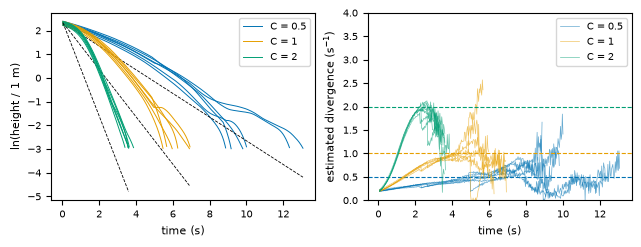

In [12]:
CHECK_CS = [0.5, 1.0, 2.0]
checks = {}
for c in CHECK_CS:
    checks[c] = [rollout(task, avb.ConstantDivergenceLandingModel(divergence=c), task.generate_trial(s)) for s in range(avb.scaled(6, 2))]

fig, axes = avb.new_figure(16, 6, 1, 2)
for c, color in zip(CHECK_CS, (BLUE, ORANGE, GREEN)):
    for k, (t, z, v, d_hat) in enumerate(checks[c]):
        axes[0].plot(t, np.log(z), color=color, lw=0.7, label=f"C = {c:g}" if k == 0 else None)
        axes[1].plot(t, d_hat, color=color, lw=0.5, alpha=0.6, label=f"C = {c:g}" if k == 0 else None)
    t0 = checks[c][0]
    axes[0].plot(t0[0], np.log(t0[1][0]) - c * (t0[0] - t0[0][0]), color="k", ls="--", lw=0.6)
    axes[1].axhline(c, color=color, ls="--", lw=0.8)
axes[0].set_xlabel("time (s)"); axes[0].set_ylabel("ln(height / 1 m)"); axes[0].legend()
axes[1].set_xlabel("time (s)"); axes[1].set_ylabel(r"estimated divergence (s$^{-1}$)"); axes[1].set_ylim(0, 4); axes[1].legend()
save(fig, "04_checks_regulation")

monotone = all(np.all(np.diff(z) <= 1e-9) for episodes_ in checks.values() for (_, z, _, _) in episodes_)
print("height decreases monotonically in every episode:", monotone)
for c in CHECK_CS:
    late = np.concatenate([d[int(0.5 * len(d)):] for (_, _, _, d) in checks[c]])
    slope = np.mean([np.polyfit(t[len(t) // 2:], np.log(z[len(z) // 2:]), 1)[0] for (t, z, _, _) in checks[c]])
    print(f"C = {c:g}: median estimated divergence in the second half {np.nanmedian(late):.2f}, slope of ln(height) in the second half {slope:.2f} (theory {-c:g})")

**2. The duration decreases and the contact speed increases with the set point.** This is the trade-off of the
front above; the check below is a direct test on the data of the front. The ideal contact speed $C z_c$ is only
$0.0125$ to $0.2$ m/s here, so for the smallest set points the contact speed is set by the **floor** of about
0.16 m/s that the gusts and the noise of the estimate leave: it does not decrease any further, and it rises
only for the set points that are large enough, $C \geq 1$.

In [13]:
T = [np.mean([r.info["time_to_land"] for r in res.trial_results]) for res in front_results["constant divergence"]]
V = [np.mean([r.info["contact_speed"] for r in res.trial_results]) for res in front_results["constant divergence"]]
print("set points            :", CS)
print("mean time to land (s) :", np.round(T, 2), "-> decreasing:", bool(np.all(np.diff(T) < 0)))
print("mean contact speed    :", np.round(V, 3), "-> increasing from C = 1:", bool(np.all(np.diff(V[2:]) > 0)),
      "| floor (smallest of them):", round(min(V), 3), "m/s")

set points            : [0.25, 0.5, 1.0, 2.0, 4.0]
mean time to land (s) : [17.11 10.15  6.21  3.44  1.92] -> decreasing: True
mean contact speed    : [0.158 0.172 0.157 0.199 0.361] -> increasing from C = 1: True | floor (smallest of them): 0.157 m/s
